# Bird-Predict MVP: Pallid Swift High-Count Days

Compare a seasonal baseline, logistic regression, and random forest for the operational target `n_records >= 10`. Evaluation uses leave-one-year-out predictions: each held-out year is predicted only by models fitted to other years. Preprocessing is fit within each training fold.

**Interpretation:** this target identifies days with at least ten GBIF reports, not independently confirmed biological influx. Reports depend on observer effort; days with no records are not confirmed absences. The dataset contains few positive years and clustered multi-day events, so all results are exploratory. Leave-one-year-out also trains on years later than the held-out year; it is not a strict forward-in-time deployment simulation.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score, precision_score, recall_score, roc_auc_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

data_path = Path("data/processed/bird_predict_dataset.csv")
df = pd.read_csv(data_path, parse_dates=["date"]).sort_values("date").reset_index(drop=True)

target_name = "high_count_day"
df[target_name] = df["n_records"].ge(10).astype(int)
df["month"] = df["date"].dt.month
df["day_of_year"] = df["date"].dt.dayofyear
wind_angle = np.deg2rad(df["DDVEC"])
df["wind_sin"] = np.sin(wind_angle)
df["wind_cos"] = np.cos(wind_angle)
day_angle = 2 * np.pi * (df["day_of_year"] - 1) / 365.25
df["day_sin"] = np.sin(day_angle)
df["day_cos"] = np.cos(day_angle)

weather_features = ["FG", "FHX", "TG", "TX", "PX", "RH", "wind_sin", "wind_cos"]
numeric_features = weather_features + ["day_sin", "day_cos"]
categorical_features = ["month"]
model_features = numeric_features + categorical_features
target = df[target_name]

if df[model_features].isna().any().any():
    raise ValueError("Unexpected missing predictor values; inspect the processed dataset before training.")

print(f"Rows: {len(df):,}; dates: {df.date.min():%Y-%m-%d} to {df.date.max():%Y-%m-%d}")
print(f"Target: n_records >= 10; positive days: {int(target.sum())}; positive rate: {target.mean():.2%}")
print(f"Predictors: {', '.join(model_features)}")
display(df[["date", "n_records", target_name, "month", "day_of_year", "wind_sin", "wind_cos"]].head())

Rows: 6,116; dates: 2010-01-10 to 2026-10-08
Target: n_records >= 10; positive days: 45; positive rate: 0.74%
Predictors: FG, FHX, TG, TX, PX, RH, wind_sin, wind_cos, day_sin, day_cos, month


,date,n_records,high_count_day,month,day_of_year,wind_sin,wind_cos
0,2010-01-10,0,0,1,10,0.829038,0.559193
1,2010-01-11,0,0,1,11,0.906308,0.422618
2,2010-01-12,0,0,1,12,0.987688,-0.156434
3,2010-01-13,0,0,1,13,0.939693,-0.342020
4,2010-01-14,0,0,1,14,0.945519,-0.325568


## Leave-one-year-out evaluation

The seasonal baseline estimates each calendar month's target rate from the training years, shrunk slightly toward the training-wide rate to avoid extreme estimates in months with few days. Logistic regression and random forest use weather plus seasonality; the random forest receives numeric month and cyclic day-of-year components. All models use a fixed probability cutoff of 0.5 for precision and recall; threshold tuning is deliberately avoided on this small dataset. ROC-AUC and average precision (reported as PR-AUC) are undefined for a fold without positive test examples, so those fold values are left missing. Overall metrics pool all out-of-fold daily predictions.

In [2]:
def make_preprocessor():
    return ColumnTransformer(
        transformers=[
            ("numeric", Pipeline([("imputer", SimpleImputer(strategy="median")), ("scale", StandardScaler())]), numeric_features),
            ("month", OneHotEncoder(handle_unknown="ignore", sparse_output=False), categorical_features),
        ],
        remainder="drop",
    )


def make_models():
    return {
        "Seasonal baseline": None,
        "Logistic regression": Pipeline(
            [
                ("preprocess", make_preprocessor()),
                ("model", LogisticRegression(class_weight="balanced", C=0.1, max_iter=2000, random_state=42)),
            ]
        ),
        "Random forest": Pipeline(
            [
                ("preprocess", make_preprocessor()),
                ("model", RandomForestClassifier(
                    n_estimators=300,
                    min_samples_leaf=5,
                    max_features="sqrt",
                    class_weight="balanced_subsample",
                    n_jobs=-1,
                    random_state=42,
                )),
            ]
        ),
    }


def binary_metrics(y_true, probabilities):
    predictions = (probabilities >= 0.5).astype(int)
    return {
        "ROC-AUC": roc_auc_score(y_true, probabilities) if pd.Series(y_true).nunique() == 2 else np.nan,
        "PR-AUC (average precision)": average_precision_score(y_true, probabilities) if np.asarray(y_true).sum() else np.nan,
        "Recall @ 0.5": recall_score(y_true, predictions, zero_division=0),
        "Precision @ 0.5": precision_score(y_true, predictions, zero_division=0),
    }


years = sorted(df["date"].dt.year.unique())
oof = pd.DataFrame({"date": df["date"], "year": df["date"].dt.year, "actual": target})
fold_metric_rows = []
logistic_importances = []
forest_importances = []

for year in years:
    test_mask = df["date"].dt.year.eq(year)
    train_mask = ~test_mask
    X_train = df.loc[train_mask, model_features]
    X_test = df.loc[test_mask, model_features]
    y_train = target.loc[train_mask]
    y_test = target.loc[test_mask]
    if y_train.nunique() < 2:
        raise ValueError(f"Training fold excluding {year} does not contain both target classes.")

    overall_training_rate = y_train.mean()
    month_counts = pd.DataFrame({"month": df.loc[train_mask, "month"], "target": y_train}).groupby("month")["target"].agg(["sum", "count"])
    smoothing_strength = 1.0
    monthly_rate = (month_counts["sum"] + smoothing_strength * overall_training_rate) / (month_counts["count"] + smoothing_strength)
    baseline_probability = df.loc[test_mask, "month"].map(monthly_rate).fillna(overall_training_rate).to_numpy()
    oof.loc[test_mask, "Seasonal baseline"] = baseline_probability

    models = make_models()
    for name in ["Logistic regression", "Random forest"]:
        model = models[name]
        model.fit(X_train, y_train)
        probabilities = model.predict_proba(X_test)[:, 1]
        oof.loc[test_mask, name] = probabilities

        preprocessor = model.named_steps["preprocess"]
        transformed_names = preprocessor.get_feature_names_out()
        if name == "Logistic regression":
            raw_importance = np.abs(model.named_steps["model"].coef_[0])
        else:
            raw_importance = model.named_steps["model"].feature_importances_
        importance_rows = []
        for transformed_name, importance in zip(transformed_names, raw_importance):
            name_parts = transformed_name.split("__", 1)
            raw_name = name_parts[-1]
            if raw_name.startswith("month_"):
                group_name = "month"
            elif raw_name in {"wind_sin", "wind_cos"}:
                group_name = "DDVEC (wind_sin/wind_cos)"
            elif raw_name in {"day_sin", "day_cos"}:
                group_name = "day_of_year (cyclic)"
            else:
                group_name = raw_name
            importance_rows.append({"feature": group_name, "importance": importance})
        grouped_importance = pd.DataFrame(importance_rows).groupby("feature")["importance"].sum()
        grouped_importance = grouped_importance / grouped_importance.sum()
        if name == "Logistic regression":
            logistic_importances.append(grouped_importance.rename(year))
        else:
            forest_importances.append(grouped_importance.rename(year))

    fold_metric_rows.append(
        {
            "test_year": year,
            "positive_days": int(y_test.sum()),
            "test_days": len(y_test),
            **{f"{name} | {metric}": value for name, column in [("Seasonal baseline", "Seasonal baseline"), ("Logistic regression", "Logistic regression"), ("Random forest", "Random forest")] for metric, value in binary_metrics(y_test, oof.loc[test_mask, column].to_numpy()).items()},
        }
    )

fold_metrics = pd.DataFrame(fold_metric_rows).set_index("test_year")
overall_rows = []
for name in ["Seasonal baseline", "Logistic regression", "Random forest"]:
    overall_rows.append({"model": name, **binary_metrics(oof["actual"], oof[name].to_numpy())})
overall_metrics = pd.DataFrame(overall_rows).set_index("model")

print("Pooled out-of-fold metrics (decision metrics use probability >= 0.5):")
display(overall_metrics.round(4))
print("Leave-one-year-out fold metrics; ROC-AUC / PR-AUC are blank when that year has no positive test examples:")
display(fold_metrics.round(4))

Pooled out-of-fold metrics (decision metrics use probability >= 0.5):


,ROC-AUC,PR-AUC (average precision),Recall @ 0.5,Precision @ 0.5
model,,,,
Seasonal baseline,0.9075,0.0410,0.0000,0.0000
Logistic regression,0.9653,0.1409,0.9556,0.0668
Random forest,0.9442,0.1895,0.2222,0.1667


Leave-one-year-out fold metrics; ROC-AUC / PR-AUC are blank when that year has no positive test examples:


,positive_days,test_days,Seasonal baseline | ROC-AUC,Seasonal baseline | PR-AUC (average precision),Seasonal baseline | Recall @ 0.5,Seasonal baseline | Precision @ 0.5,Logistic regression | ROC-AUC,Logistic regression | PR-AUC (average precision),Logistic regression | Recall @ 0.5,Logistic regression | Precision @ 0.5,Random forest | ROC-AUC,Random forest | PR-AUC (average precision),Random forest | Recall @ 0.5,Random forest | Precision @ 0.5
test_year,,,,,,,,,,,,,,
2010,0,356,NaN,NaN,0.0,0.0,NaN,NaN,0.0000,0.0000,NaN,NaN,0.0000,0.0000
2011,0,365,NaN,NaN,0.0,0.0,NaN,NaN,0.0000,0.0000,NaN,NaN,0.0000,0.0000
2012,0,366,NaN,NaN,0.0,0.0,NaN,NaN,0.0000,0.0000,NaN,NaN,0.0000,0.0000
2013,3,365,0.9332,0.0594,0.0,0.0,0.9890,0.3730,1.0000,0.0750,0.9871,0.5074,0.3333,0.1250
2014,5,365,0.8792,0.0820,0.0,0.0,0.9022,0.0758,1.0000,0.1087,0.7033,0.0504,0.0000,0.0000
2015,1,365,0.8750,0.0164,0.0,0.0,0.9835,0.1429,1.0000,0.0278,0.9588,0.0625,0.0000,0.0000
2016,0,366,NaN,NaN,0.0,0.0,NaN,NaN,0.0000,0.0000,NaN,NaN,0.0000,0.0000
2017,1,365,0.9588,0.0323,0.0,0.0,0.9890,0.2000,1.0000,0.0286,0.9615,0.0667,0.0000,0.0000
2018,3,365,0.8771,0.0492,0.0,0.0,0.9079,0.0760,0.6667,0.0606,0.9641,0.1922,0.0000,0.0000


## Feature importance

Importance is averaged over the leave-one-year-out training folds. Logistic regression reports mean absolute standardized coefficient magnitude; random forest reports mean impurity importance. Month and the two wind-direction components are grouped for easier interpretation. These rankings are model-specific and do not imply causation.

In [3]:
feature_importance = pd.DataFrame(
    {
        "Logistic regression | mean abs. coefficient": pd.concat(logistic_importances, axis=1).mean(axis=1),
        "Random forest | mean importance": pd.concat(forest_importances, axis=1).mean(axis=1),
    }
).fillna(0)
for column in feature_importance:
    feature_importance[f"{column} rank"] = feature_importance[column].rank(ascending=False, method="min").astype(int)
display(feature_importance.sort_values("Random forest | mean importance", ascending=False).round(4))

,Logistic regression | mean abs. coefficient,Random forest | mean importance,Logistic regression | mean abs. coefficient rank,Random forest | mean importance rank
feature,,,,
day_of_year (cyclic),0.2888,0.4557,2,1
month,0.4663,0.1457,1,2
DDVEC (wind_sin/wind_cos),0.0766,0.1316,3,3
TG,0.0354,0.0892,5,4
TX,0.0322,0.0791,6,5
PX,0.0257,0.0477,8,6
FG,0.0404,0.0243,4,7
RH,0.0045,0.0137,9,8
FHX,0.0301,0.0130,7,9


## Out-of-fold predicted probabilities through time

Each point is a held-out-year prediction, not an in-sample fitted probability. Red vertical marks indicate target-positive days.

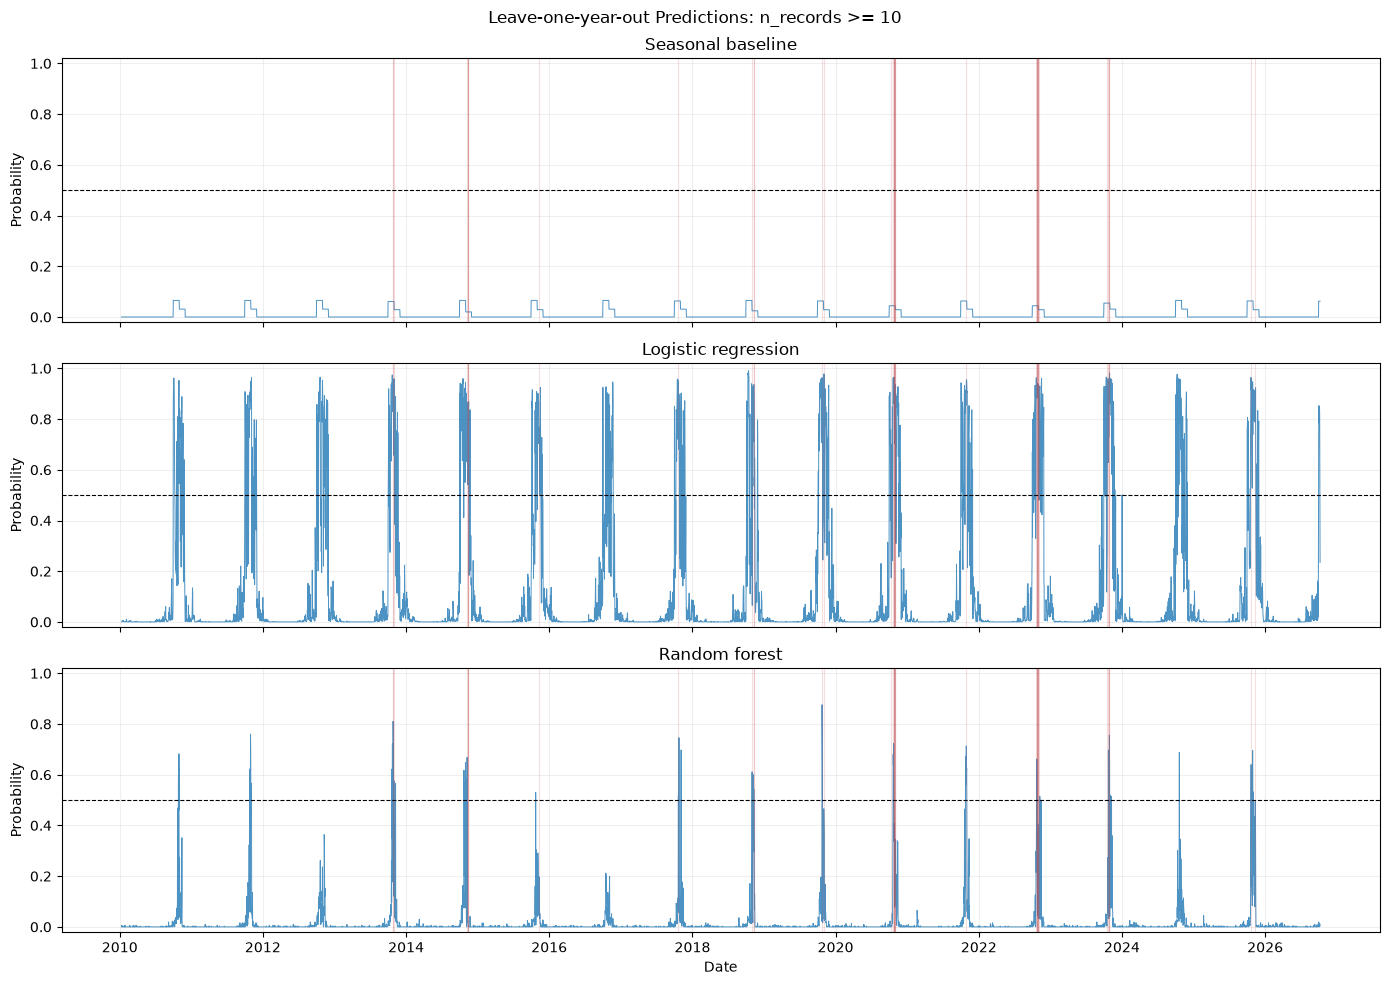

In [4]:
model_names = ["Seasonal baseline", "Logistic regression", "Random forest"]
fig, axes = plt.subplots(len(model_names), 1, figsize=(14, 10), sharex=True)
positive_dates = oof.loc[oof["actual"].eq(1), "date"]
for ax, name in zip(axes, model_names):
    ax.plot(oof["date"], oof[name], linewidth=0.7, alpha=0.8, label="Out-of-fold probability")
    for event_date in positive_dates:
        ax.axvline(event_date, color="#c44e52", alpha=0.18, linewidth=0.8)
    ax.axhline(0.5, color="black", linestyle="--", linewidth=0.8, label="0.5 decision cutoff")
    ax.set_ylabel("Probability")
    ax.set_ylim(-0.02, 1.02)
    ax.set_title(name)
    ax.grid(alpha=0.2)
axes[-1].set_xlabel("Date")
fig.suptitle("Leave-one-year-out Predictions: n_records >= 10")
fig.tight_layout()
plt.show()

## MVP recommendation

Start with the seasonal monthly-rate baseline and retain it as the benchmark. In this run, pooled leave-one-year-out average precision was 0.041 for the baseline, 0.141 for logistic regression, and 0.190 for random forest. At the fixed 0.5 cutoff, logistic regression recalled 95.6% of positive days but precision was 6.7%; random forest precision was 16.7% and recall 22.2%. The forest therefore ranks days better by average precision in this run, while the logistic model catches more positives at the chosen cutoff. These tradeoffs are unstable with only 45 positive days. Do not select a model on ROC-AUC alone: prioritize average precision, event-level recall, calibration, and false alarms per season. The fixed 0.5 precision/recall metrics are comparability diagnostics, not an optimized operational alert threshold.

The current `>=10` target yields only 45 labeled days, clustered into a smaller number of weather episodes. Leave-one-year-out estimates remain noisy and use future years in some training folds. Before deployment, gather more years and observation-effort information, then add a strictly forward-chaining evaluation that trains only on past years and holds out complete future migration seasons. Interpret weather importances as candidate predictors for further testing, not biological evidence that weather causes Pallid Swift vagrancy.